### Tools

Models can request to call tools that perform tasks such as fetching data from a database,searching the web, or running code. 

Tools are pairings of:
1. A schema, inculding the name of the tool, a description and/or arugment definitions(often a JSON schema)
2. A function or coroutine to execute.

In [2]:

import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()

model = init_chat_model(
    "openai/gpt-oss-120b",
    model_provider="groq"
)

response = model.invoke("Why do parrots talk?")
print(response.content)


**Short answer:**  
Parrots don’t “talk” the way humans do—they are superb vocal mimics. Their ability to copy human speech (and other sounds) evolved for social communication within their own species, and the same brain and vocal‑tract adaptations happen to let them imitate the noises they hear in captivity.

---

## 1. The biological basis of vocal learning

| Feature | What it is | Why it matters for “talking” |
|---------|------------|------------------------------|
| **Vocal learning** | The capacity to acquire new sounds by listening to and practicing them, rather than being born with a fixed repertoire. | Only a handful of animal groups (songbirds, hummingbirds, some mammals, and all parrots) can do this. It lets a parrot copy human words. |
| **Brain structures** | • **Nucleus robustus archistriatalis (RA)** – motor control of the syrinx (bird’s voice box). <br>• **Nucleus magnocellularis of the anterior nidopallium (NCM)** – auditory memory and discrimination. <br>• **Higher v

In [4]:
from langchain.tools import  tool

@tool
def get_weather(locacation:str)->str:
    """Get the weather at a location"""
    return f"It's sunny in {location}"

model_with_tools = model.bind_tools([get_weather])

In [16]:
response = model_with_tools.invoke("What's the weather like in Boston")
print(response)
for tool_call in response.tool_calls:
    #View tools calls made by the model
    print(f"Tool: {tool_call['name']}")
    print(f"Args: {tool_call['args']}")


content='' additional_kwargs={'reasoning_content': 'The user asks: "What\'s the weather like in Boston". We need to get weather via function get_weather. Note the function expects parameter "locacation" (typo). Should we pass "Boston"? Probably need to pass the location string. The parameter name is "locacation". We\'ll call function.', 'tool_calls': [{'id': 'fc_6549bec6-a700-4438-8eb3-00d70cf337b3', 'function': {'arguments': '{"locacation":"Boston"}', 'name': 'get_weather'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 93, 'prompt_tokens': 128, 'total_tokens': 221, 'completion_time': 0.191869039, 'completion_tokens_details': {'reasoning_tokens': 64}, 'prompt_time': 0.018549859, 'prompt_tokens_details': None, 'queue_time': 0.254658445, 'total_time': 0.210418898}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_90620edd96', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--0

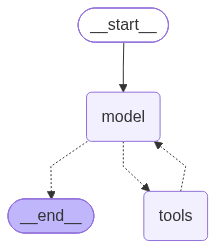

In [15]:
from langchain.agents import create_agent

def get_weather(city:str)->str:
    """ Get the weather for a city."""
    return f"The weather in {city} is sunny."

agent = create_agent(
    model="gpt-5",
    tools = [get_weather],
    system_prompt = "You are a helpfull assistant."
)
agent

### Tool Execution Loops

In [19]:

from langchain.tools import tool

@tool
def get_weather(location: str) -> str:
    """Get the weather for a given location."""
    return f"The weather in {location} is sunny."


In [20]:

tools = [get_weather]

model_with_tools = model.bind_tools(tools)


In [21]:

from langchain.messages import ToolMessage

messages = [
    {"role": "user", "content": "What's the weather in Boston?"}
]

ai_msg = model_with_tools.invoke(messages)
messages.append(ai_msg)

for tool_call in ai_msg.tool_calls:
    tool_result = get_weather.invoke(tool_call["args"])

    messages.append(
        ToolMessage(
            content=str(tool_result),
            tool_call_id=tool_call["id"]
        )
    )

final_response = model_with_tools.invoke(messages)
print(final_response.content)


The current weather in Boston is sunny.


In [22]:
messages

[{'role': 'user', 'content': "What's the weather in Boston?"},
 AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks for weather in Boston. We have a function get_weather. Use it.', 'tool_calls': [{'id': 'fc_5297171b-e7f4-41bb-88d3-872e5101c3a8', 'function': {'arguments': '{"location":"Boston"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 127, 'total_tokens': 173, 'completion_time': 0.096342195, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.005364493, 'prompt_tokens_details': None, 'queue_time': 0.244412988, 'total_time': 0.101706688}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c868cf1eaa', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a149d8-0650-7d10-b9e8-e554da5b047f-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Boston'}, 'id': 'fc_5297171b-e7f4-4